In [2]:
import pandas as pd


In [4]:
df = pd.read_csv("C:/Users/91639/Downloads/personal_finance_tracker_dataset.csv")


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
print(df.shape)

(3000, 25)


In [7]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   date                    3000 non-null   object 
 1   user_id                 3000 non-null   int64  
 2   monthly_income          3000 non-null   float64
 3   monthly_expense_total   3000 non-null   float64
 4   savings_rate            3000 non-null   float64
 5   budget_goal             3000 non-null   float64
 6   financial_scenario      3000 non-null   object 
 7   credit_score            3000 non-null   float64
 8   debt_to_income_ratio    3000 non-null   float64
 9   loan_payment            3000 non-null   float64
 10  investment_amount       3000 non-null   float64
 11  subscription_services   3000 non-null   int64  
 12  emergency_fund          3000 non-null   float64
 13  transaction_count       3000 non-null   int64  
 14  fraud_flag              3000 non-null   

In [8]:

obj_cols = df.select_dtypes(include='object').columns
print(obj_cols) 
print(df['financial_advice_score'].unique()[:20])
print(df['financial_advice_score'].apply(type).value_counts())

Index(['date', 'financial_scenario', 'income_type', 'category',
       'cash_flow_status', 'financial_stress_level'],
      dtype='object')
[ 8.3 22.6 58.8 74.5 38.7 53.7 74.7 83.1 71.6 77.9 62.5 36.1 39.  17.2
 11.2 94.2 50.  68.6 90.6 73.7]
financial_advice_score
<class 'float'>    3000
Name: count, dtype: int64


In [9]:


# 1. Date → datetime
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# 2. financial_advice_score → numeric
df['financial_advice_score'] = pd.to_numeric(
    df['financial_advice_score'], errors='coerce'
)

# 3. Booleans
df['fraud_flag'] = df['fraud_flag'].astype(bool)
df['savings_goal_met'] = df['savings_goal_met'].astype(bool)

# 4. Categorical
cat_cols = ['financial_scenario', 'income_type', 'category',
            'cash_flow_status', 'financial_stress_level']
for col in cat_cols:
    df[col] = df[col].astype('category')

# 5. Verify
print(df.info())
print("\nNulls after conversion:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   date                    3000 non-null   datetime64[ns]
 1   user_id                 3000 non-null   int64         
 2   monthly_income          3000 non-null   float64       
 3   monthly_expense_total   3000 non-null   float64       
 4   savings_rate            3000 non-null   float64       
 5   budget_goal             3000 non-null   float64       
 6   financial_scenario      3000 non-null   category      
 7   credit_score            3000 non-null   float64       
 8   debt_to_income_ratio    3000 non-null   float64       
 9   loan_payment            3000 non-null   float64       
 10  investment_amount       3000 non-null   float64       
 11  subscription_services   3000 non-null   int64         
 12  emergency_fund          3000 non-null   float64 

In [10]:
print("Date range:", df['date'].min(), "→", df['date'].max())
print("savings_rate:", df['savings_rate'].min(), "→", df['savings_rate'].max())
print("credit_score:", df['credit_score'].min(), "→", df['credit_score'].max())
print("DTI:", df['debt_to_income_ratio'].min(), "→", df['debt_to_income_ratio'].max())
print("income:", df['monthly_income'].min(), "→", df['monthly_income'].max())

Date range: 2019-01-01 00:00:00 → 2023-11-06 00:00:00
savings_rate: 0.05 → 0.4
credit_score: 515.0 → 847.0
DTI: 0.1 → 0.6
income: 685.28 → 7407.94


In [12]:
df['year']       = df['date'].dt.year
df['month']      = df['date'].dt.month
df['month_name'] = df['date'].dt.strftime('%b')
df['year_month'] = df['date'].dt.to_period('M')

In [13]:
df.to_csv("cleaned_personal_finance.csv", index=False)
print("✅ Saved")

✅ Saved


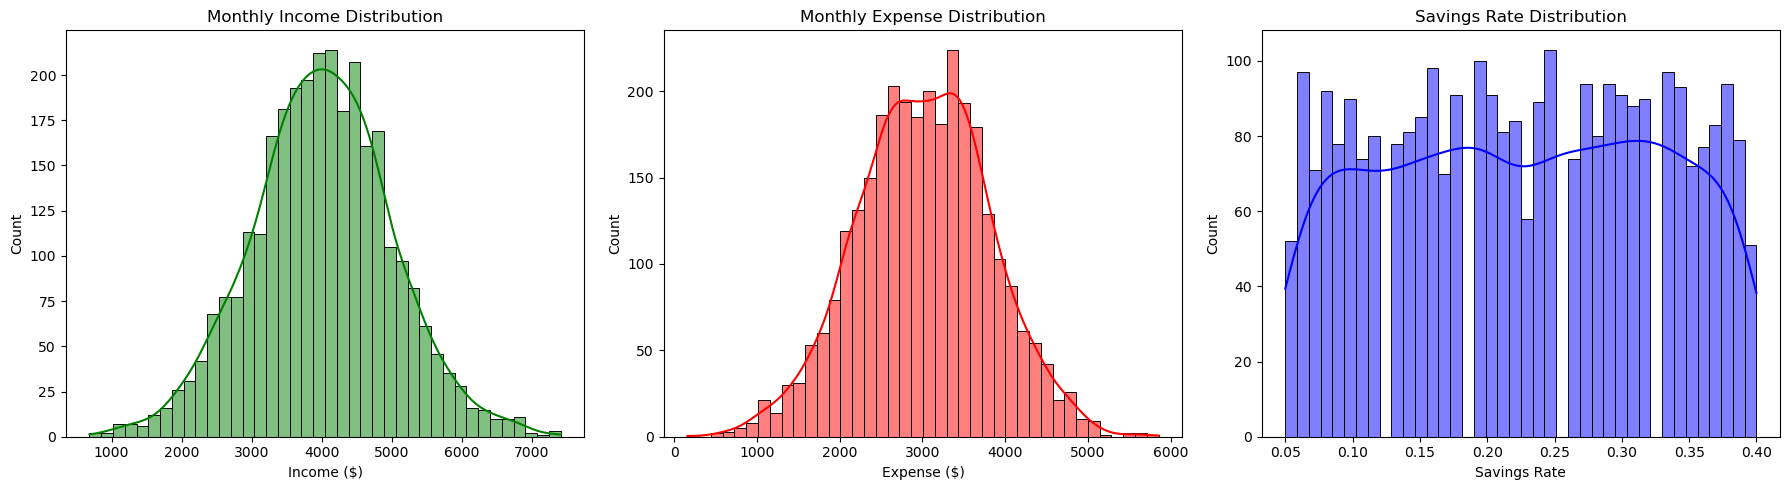

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['monthly_income'], bins=40, kde=True, ax=axes[0], color='green')
axes[0].set_title('Monthly Income Distribution')
axes[0].set_xlabel('Income ($)')

sns.histplot(df['monthly_expense_total'], bins=40, kde=True, ax=axes[1], color='red')
axes[1].set_title('Monthly Expense Distribution')
axes[1].set_xlabel('Expense ($)')

sns.histplot(df['savings_rate'], bins=40, kde=True, ax=axes[2], color='blue')
axes[2].set_title('Savings Rate Distribution')
axes[2].set_xlabel('Savings Rate')

plt.tight_layout()
plt.show()

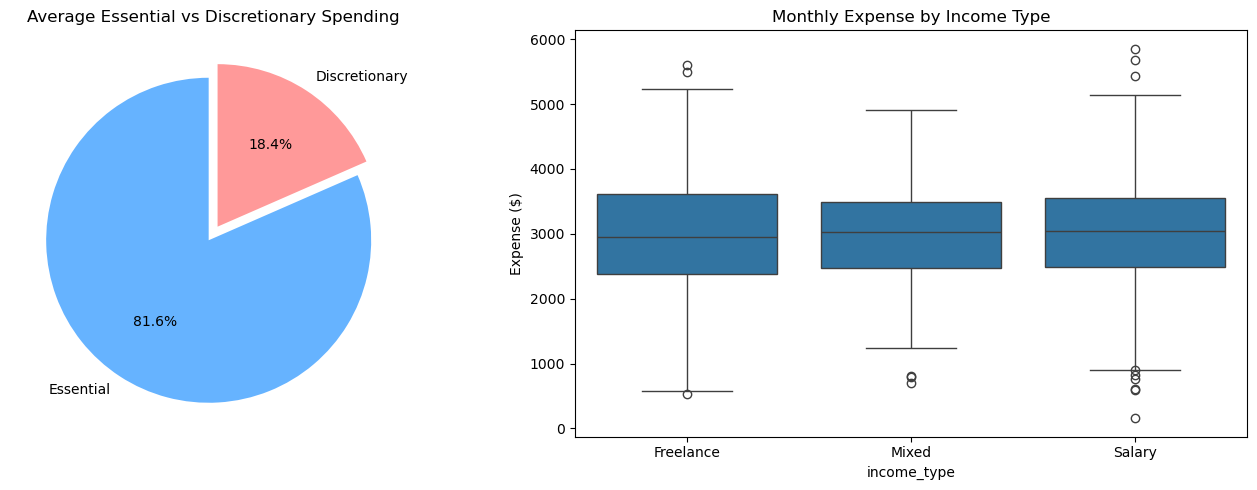

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie: Essential vs Discretionary (average)
avg_split = df[['essential_spending','discretionary_spending']].mean()
axes[0].pie(avg_split, labels=['Essential','Discretionary'], 
            autopct='%1.1f%%', colors=['#66b3ff','#ff9999'],
            startangle=90, explode=(0.05, 0.05))
axes[0].set_title('Average Essential vs Discretionary Spending')

# Box: Spending by income type
sns.boxplot(data=df, x='income_type', y='monthly_expense_total', ax=axes[1])
axes[1].set_title('Monthly Expense by Income Type')
axes[1].set_ylabel('Expense ($)')

plt.tight_layout()
plt.show()

C:\Users\91639\AppData\Local\Temp\ipykernel_11532\1440515323.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='financial_scenario', y='discretionary_spending',
C:\Users\91639\AppData\Local\Temp\ipykernel_11532\1440515323.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  scenario_avg = df.groupby('financial_scenario')[


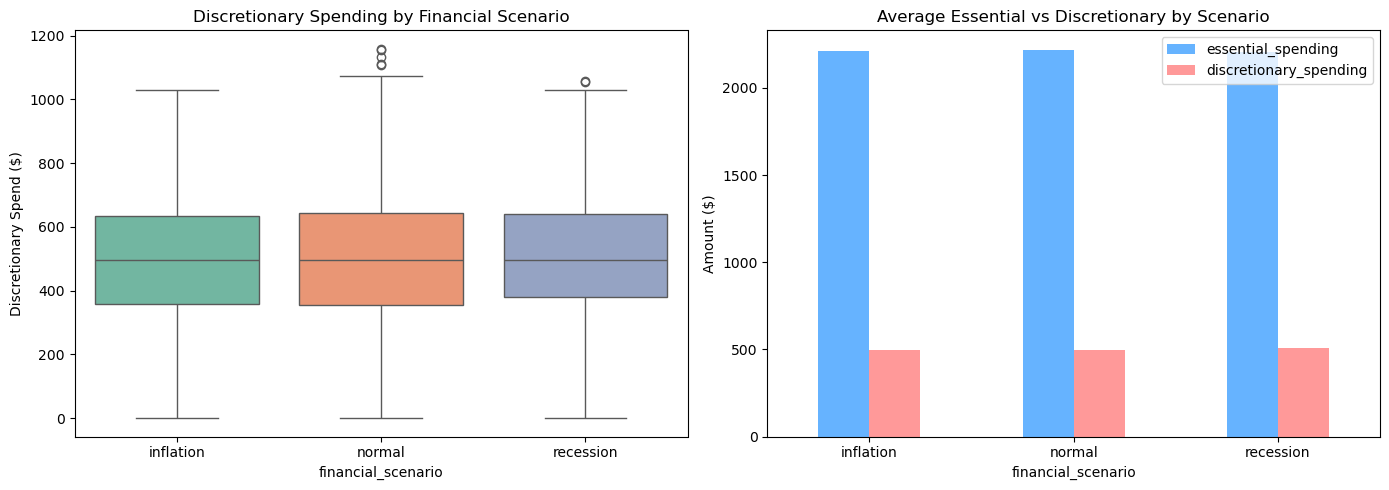

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Discretionary spend by financial scenario
sns.boxplot(data=df, x='financial_scenario', y='discretionary_spending', 
            ax=axes[0], palette='Set2')
axes[0].set_title('Discretionary Spending by Financial Scenario')
axes[0].set_ylabel('Discretionary Spend ($)')

# 2. Average spend by scenario
scenario_avg = df.groupby('financial_scenario')[
    ['essential_spending','discretionary_spending']
].mean()
scenario_avg.plot(kind='bar', ax=axes[1], color=['#66b3ff','#ff9999'])
axes[1].set_title('Average Essential vs Discretionary by Scenario')
axes[1].set_ylabel('Amount ($)')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [18]:
import warnings

# Hide only FutureWarnings
warnings.filterwarnings('ignore', category=FutureWarning)

# Hide only the pandas observed warning
warnings.filterwarnings('ignore', message='.*observed=False.*')

# Hide only seaborn palette warning
warnings.filterwarnings('ignore', message='.*palette.*')

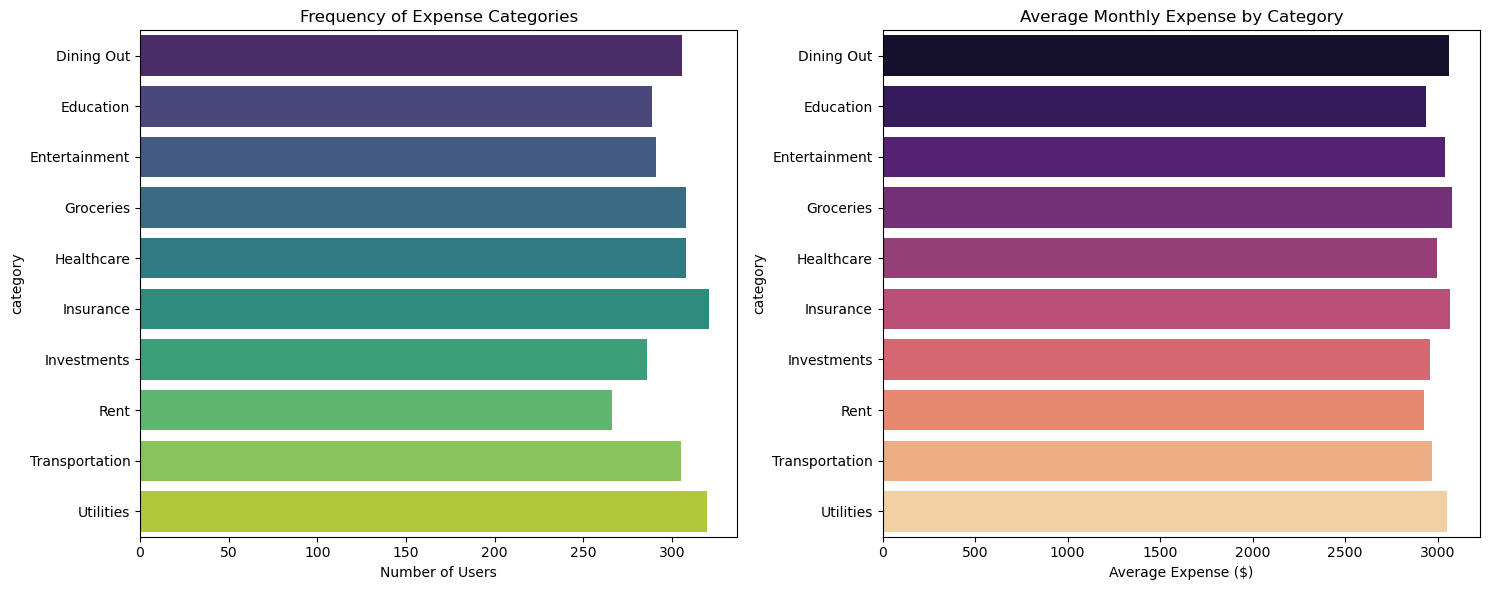

Top 5 categories by frequency:
category
Insurance     321
Utilities     320
Groceries     308
Healthcare    308
Dining Out    306
Name: count, dtype: int64

Top 5 categories by average spend:
category
Groceries        3075.907468
Insurance        3069.759283
Dining Out       3064.683529
Utilities        3050.103219
Entertainment    3040.614536
Name: monthly_expense_total, dtype: float64


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Frequency of each category
cat_counts = df['category'].value_counts()
sns.barplot(x=cat_counts.values, y=cat_counts.index, ax=axes[0], palette='viridis')
axes[0].set_title('Frequency of Expense Categories')
axes[0].set_xlabel('Number of Users')

# 2. Average expense per category
cat_spend = df.groupby('category', observed=False)['monthly_expense_total'].mean().sort_values()
sns.barplot(x=cat_spend.values, y=cat_spend.index, ax=axes[1], palette='magma')
axes[1].set_title('Average Monthly Expense by Category')
axes[1].set_xlabel('Average Expense ($)')

plt.tight_layout()
plt.show()

# Print top 5
print("Top 5 categories by frequency:")
print(cat_counts.head())
print("\nTop 5 categories by average spend:")
print(cat_spend.sort_values(ascending=False).head())

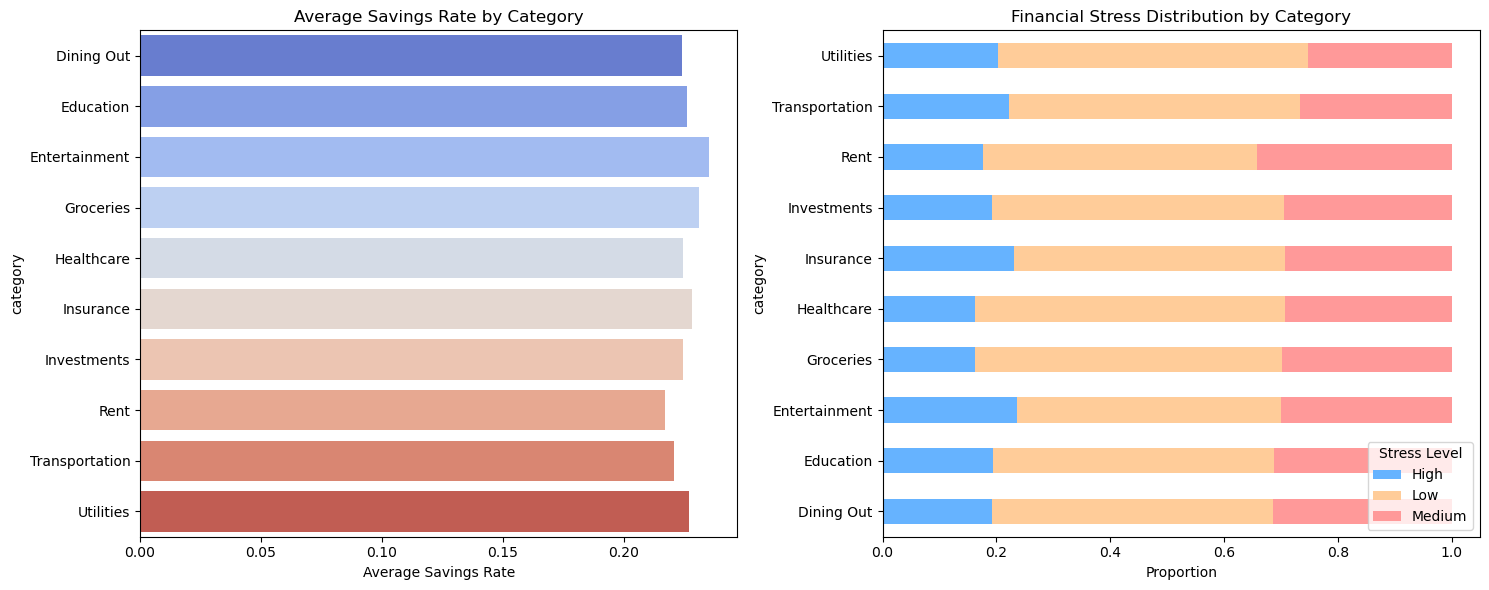

Top 3 lowest savings rate categories:
category
Rent              0.216917
Transportation    0.220852
Dining Out        0.223954
Name: savings_rate, dtype: float64

Top 3 highest savings rate categories:
category
Insurance        0.228349
Groceries        0.231071
Entertainment    0.235189
Name: savings_rate, dtype: float64


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Average savings rate by category
cat_savings = df.groupby('category', observed=False)['savings_rate'].mean().sort_values()
sns.barplot(x=cat_savings.values, y=cat_savings.index, 
            ax=axes[0], hue=cat_savings.index, palette='coolwarm', legend=False)
axes[0].set_title('Average Savings Rate by Category')
axes[0].set_xlabel('Average Savings Rate')

# 2. Financial stress level distribution by category
stress_cat = pd.crosstab(df['category'], df['financial_stress_level'], normalize='index')
stress_cat.plot(kind='barh', stacked=True, ax=axes[1], 
                color=['#66b3ff','#ffcc99','#ff9999'])
axes[1].set_title('Financial Stress Distribution by Category')
axes[1].set_xlabel('Proportion')
axes[1].legend(title='Stress Level', loc='lower right')

plt.tight_layout()
plt.show()

# Print
print("Top 3 lowest savings rate categories:")
print(cat_savings.head(3))
print("\nTop 3 highest savings rate categories:")
print(cat_savings.tail(3))

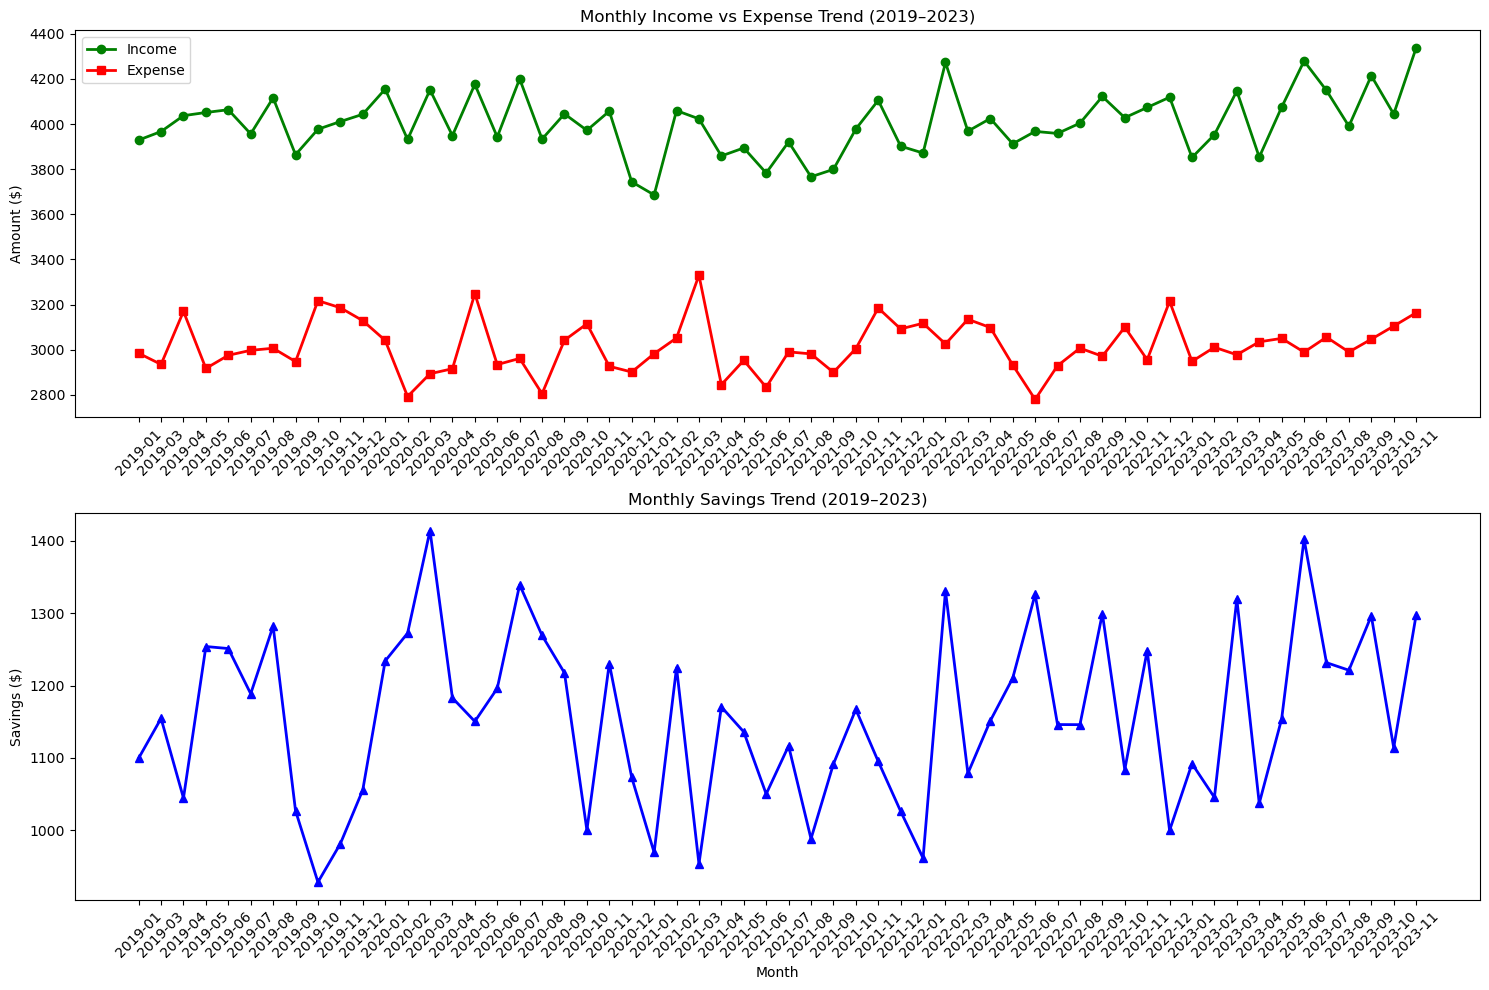

Yearly averages:
      monthly_income  monthly_expense_total  actual_savings  savings_rate
year                                                                     
2019         3999.89                3027.74         1124.70          0.23
2020         4021.64                2964.20         1215.01          0.23
2021         3898.11                3011.98         1082.46          0.22
2022         4027.01                3021.60         1165.20          0.23
2023         4081.48                3033.37         1201.08          0.23


In [21]:
# Group by month
monthly = df.groupby('year_month', observed=False)[
    ['monthly_income','monthly_expense_total','actual_savings']
].mean().reset_index()
monthly['year_month'] = monthly['year_month'].astype(str)

fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# 1. Income vs Expense over time
axes[0].plot(monthly['year_month'], monthly['monthly_income'], 
             marker='o', label='Income', color='green', linewidth=2)
axes[0].plot(monthly['year_month'], monthly['monthly_expense_total'], 
             marker='s', label='Expense', color='red', linewidth=2)
axes[0].set_title('Monthly Income vs Expense Trend (2019–2023)')
axes[0].set_ylabel('Amount ($)')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=45)

# 2. Savings trend
axes[1].plot(monthly['year_month'], monthly['actual_savings'], 
             marker='^', color='blue', linewidth=2)
axes[1].set_title('Monthly Savings Trend (2019–2023)')
axes[1].set_ylabel('Savings ($)')
axes[1].set_xlabel('Month')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Print yearly summary
print("Yearly averages:")
print(df.groupby('year', observed=False)[
    ['monthly_income','monthly_expense_total','actual_savings','savings_rate']
].mean().round(2))

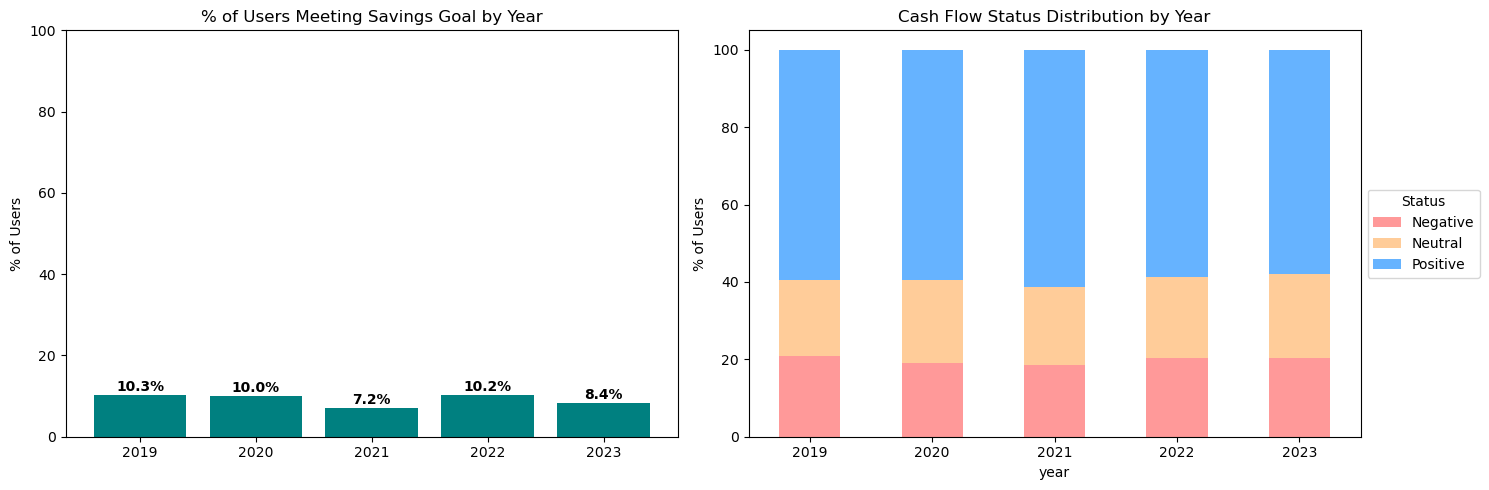

Savings goal achievement by year:
year
2019    10.3
2020    10.0
2021     7.2
2022    10.2
2023     8.4
Name: savings_goal_met, dtype: float64

Cash flow distribution:
cash_flow_status  Negative  Neutral  Positive
year                                         
2019                  20.9     19.7      59.4
2020                  19.2     21.3      59.5
2021                  18.5     20.2      61.3
2022                  20.3     20.8      58.8
2023                  20.4     21.6      58.0


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. % of users meeting savings goals per year
goal_by_year = df.groupby('year', observed=False)['savings_goal_met'].mean() * 100
axes[0].bar(goal_by_year.index.astype(str), goal_by_year.values, color='teal')
axes[0].set_title('% of Users Meeting Savings Goal by Year')
axes[0].set_ylabel('% of Users')
axes[0].set_ylim(0, 100)
for i, v in enumerate(goal_by_year.values):
    axes[0].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')

# 2. Cash flow status distribution over years
cashflow_year = pd.crosstab(df['year'], df['cash_flow_status'], normalize='index') * 100
cashflow_year.plot(kind='bar', stacked=True, ax=axes[1], 
                    color=['#ff9999','#ffcc99','#66b3ff'])
axes[1].set_title('Cash Flow Status Distribution by Year')
axes[1].set_ylabel('% of Users')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Status', loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

# Print
print("Savings goal achievement by year:")
print(goal_by_year.round(1))
print("\nCash flow distribution:")
print(cashflow_year.round(1))

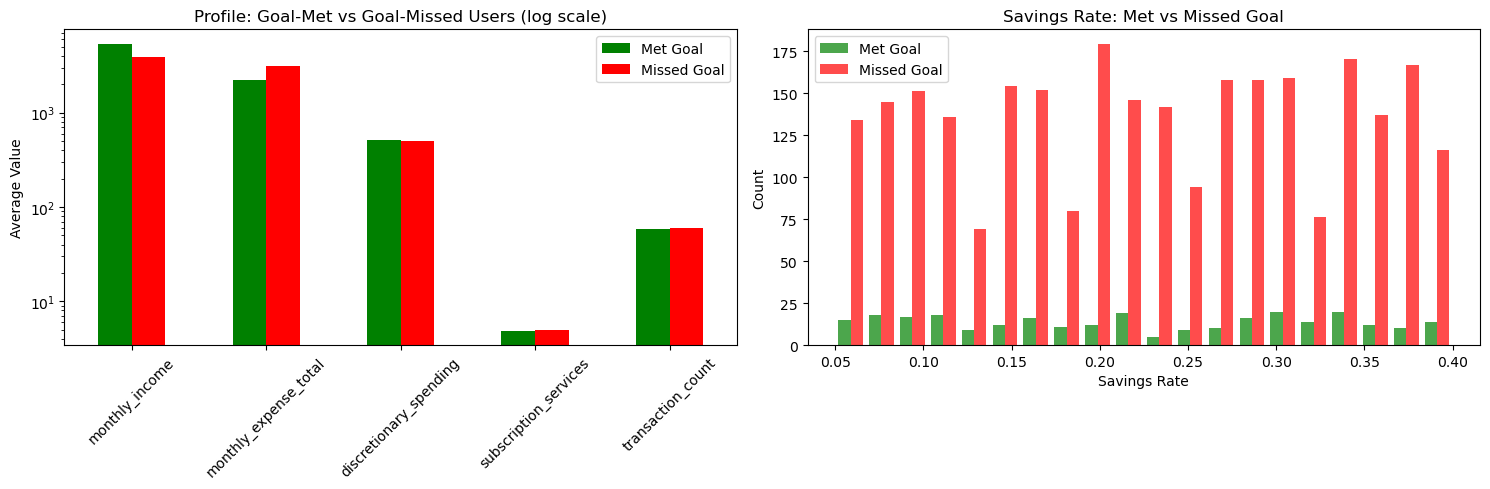

=== Goal-Met vs Goal-Missed User Profiles ===
                        Met Goal  Missed Goal
monthly_income           5369.66      3865.37
monthly_expense_total    2240.50      3090.13
discretionary_spending    506.37       500.25
subscription_services       4.87         4.99
transaction_count          58.99        59.58

Users who MET goal: 277 (9.2%)
Users who MISSED goal: 2723 (90.8%)


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Who misses goals? Profile them
missed = df[df['savings_goal_met'] == False]
met = df[df['savings_goal_met'] == True]

compare = pd.DataFrame({
    'Met Goal': met[['monthly_income','monthly_expense_total',
                     'discretionary_spending','subscription_services',
                     'transaction_count']].mean(),
    'Missed Goal': missed[['monthly_income','monthly_expense_total',
                            'discretionary_spending','subscription_services',
                            'transaction_count']].mean()
})
compare.plot(kind='bar', ax=axes[0], logy=True, color=['green','red'])
axes[0].set_title('Profile: Goal-Met vs Goal-Missed Users (log scale)')
axes[0].set_ylabel('Average Value')
axes[0].tick_params(axis='x', rotation=45)

# 2. Savings rate distribution: met vs missed
axes[1].hist([met['savings_rate'], missed['savings_rate']], 
             bins=20, label=['Met Goal','Missed Goal'],
             color=['green','red'], alpha=0.7)
axes[1].set_title('Savings Rate: Met vs Missed Goal')
axes[1].set_xlabel('Savings Rate')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.show()

# Print
print("=== Goal-Met vs Goal-Missed User Profiles ===")
print(compare.round(2))
print(f"\nUsers who MET goal: {len(met)} ({len(met)/len(df)*100:.1f}%)")
print(f"Users who MISSED goal: {len(missed)} ({len(missed)/len(df)*100:.1f}%)")

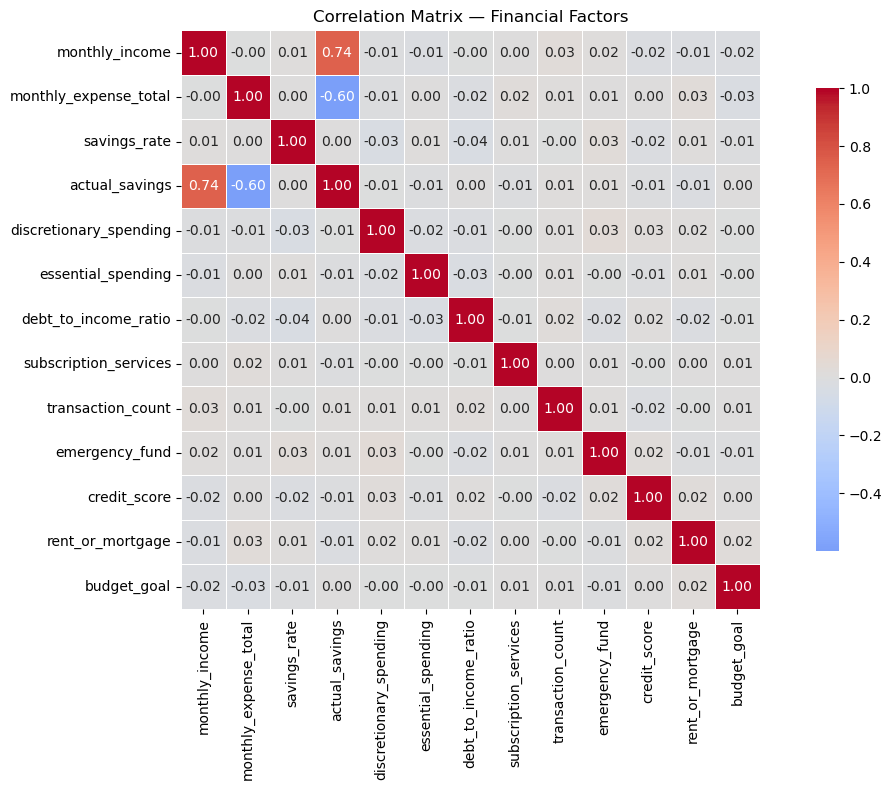

Top factors correlated with SAVINGS RATE:
savings_rate              1.000
emergency_fund            0.026
rent_or_mortgage          0.015
monthly_income            0.010
essential_spending        0.008
subscription_services     0.006
actual_savings            0.005
monthly_expense_total     0.001
transaction_count        -0.001
budget_goal              -0.012
credit_score             -0.015
discretionary_spending   -0.034
debt_to_income_ratio     -0.037
Name: savings_rate, dtype: float64


In [24]:
fig, ax = plt.subplots(figsize=(12, 8))

# Select numeric columns for correlation
corr_cols = ['monthly_income', 'monthly_expense_total', 'savings_rate',
             'actual_savings', 'discretionary_spending', 'essential_spending',
             'debt_to_income_ratio', 'subscription_services', 
             'transaction_count', 'emergency_fund', 'credit_score',
             'rent_or_mortgage', 'budget_goal']

corr_matrix = df[corr_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5, 
            cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlation Matrix — Financial Factors')
plt.tight_layout()
plt.show()

# Top correlations with savings_rate
print("Top factors correlated with SAVINGS RATE:")
print(corr_matrix['savings_rate'].sort_values(ascending=False).round(3))

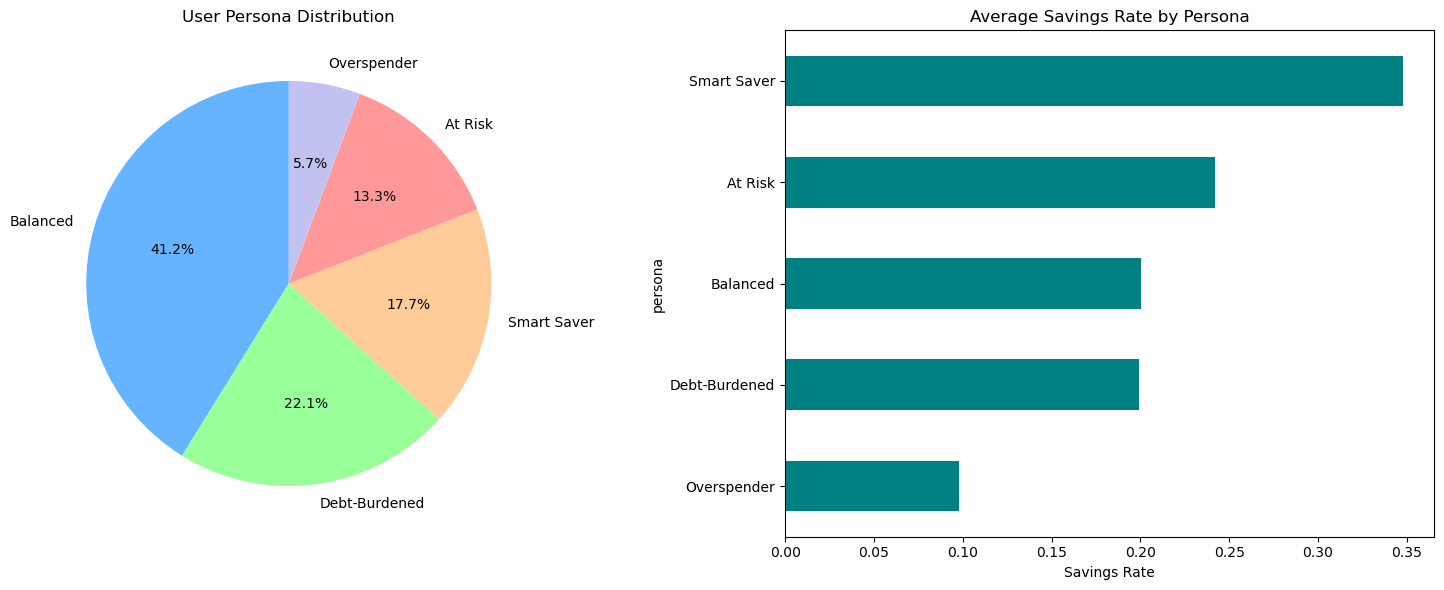

=== Persona Distribution ===
persona
Balanced         1235
Debt-Burdened     664
Smart Saver       530
At Risk           400
Overspender       171
Name: count, dtype: int64

=== Persona Profiles ===
               savings_rate  monthly_income  monthly_expense_total
persona                                                           
Overspender            0.10         2929.84                3744.75
Debt-Burdened          0.20         4094.57                2904.20
Balanced               0.20         4087.68                2980.46
At Risk                0.24         4056.12                2995.78
Smart Saver            0.35         4004.30                2994.57


In [25]:
# Create user personas based on savings behavior
def assign_persona(row):
    if row['savings_rate'] >= 0.30 and row['cash_flow_status'] == 'Positive':
        return 'Smart Saver'
    elif row['savings_rate'] < 0.15 and row['monthly_expense_total'] > row['monthly_income']:
        return 'Overspender'
    elif row['debt_to_income_ratio'] > 0.45:
        return 'Debt-Burdened'
    elif row['cash_flow_status'] == 'Negative':
        return 'At Risk'
    else:
        return 'Balanced'

df['persona'] = df.apply(assign_persona, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Persona distribution
persona_counts = df['persona'].value_counts()
colors = ['#66b3ff', '#99ff99', '#ffcc99', '#ff9999', '#c2c2f0']
axes[0].pie(persona_counts, labels=persona_counts.index, 
            autopct='%1.1f%%', startangle=90, colors=colors[:len(persona_counts)])
axes[0].set_title('User Persona Distribution')

# 2. Average savings rate by persona
persona_savings = df.groupby('persona', observed=False)[
    ['savings_rate','monthly_income','monthly_expense_total']
].mean().sort_values('savings_rate')

persona_savings['savings_rate'].plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title('Average Savings Rate by Persona')
axes[1].set_xlabel('Savings Rate')

plt.tight_layout()
plt.show()

# Print
print("=== Persona Distribution ===")
print(persona_counts)
print("\n=== Persona Profiles ===")
print(persona_savings.round(2))

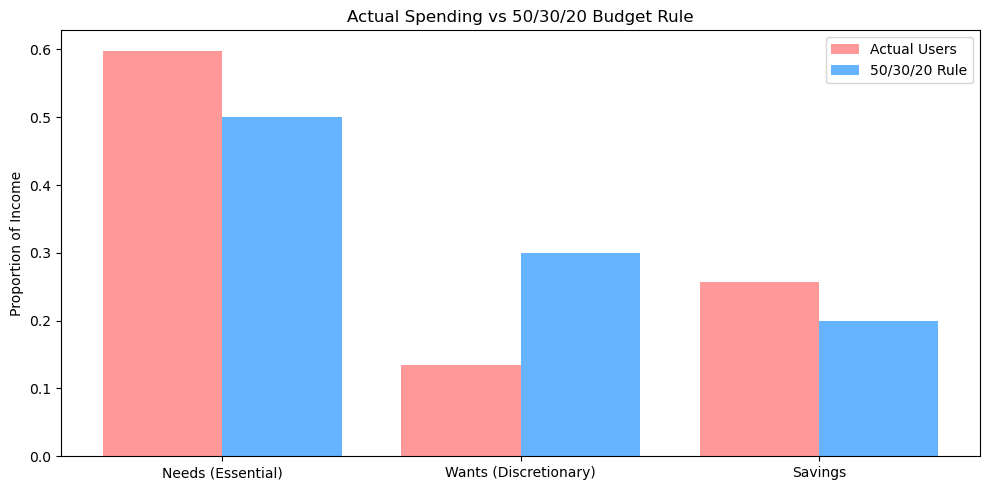

Needs:   Actual=59.83%  |  Ideal=50.00%
Wants:   Actual=13.53%  |  Ideal=30.00%
Savings: Actual=25.69%  |  Ideal=20.00%


In [26]:
# 50/30/20 Rule Analysis
df['needs_ratio']   = df['essential_spending'] / df['monthly_income']
df['wants_ratio']   = df['discretionary_spending'] / df['monthly_income']
df['savings_ratio'] = df['actual_savings'] / df['monthly_income']

avg = df[['needs_ratio','wants_ratio','savings_ratio']].mean()

fig, ax = plt.subplots(figsize=(10, 5))
x = ['Needs (Essential)', 'Wants (Discretionary)', 'Savings']
actual = [avg['needs_ratio'], avg['wants_ratio'], avg['savings_ratio']]
ideal  = [0.50, 0.30, 0.20]

x_pos = range(len(x))
ax.bar([p - 0.2 for p in x_pos], actual, width=0.4, label='Actual Users', color='#ff9999')
ax.bar([p + 0.2 for p in x_pos], ideal,  width=0.4, label='50/30/20 Rule', color='#66b3ff')
ax.set_xticks(x_pos)
ax.set_xticklabels(x)
ax.set_ylabel('Proportion of Income')
ax.set_title('Actual Spending vs 50/30/20 Budget Rule')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Needs:   Actual={avg['needs_ratio']:.2%}  |  Ideal=50.00%")
print(f"Wants:   Actual={avg['wants_ratio']:.2%}  |  Ideal=30.00%")
print(f"Savings: Actual={avg['savings_ratio']:.2%}  |  Ideal=20.00%")

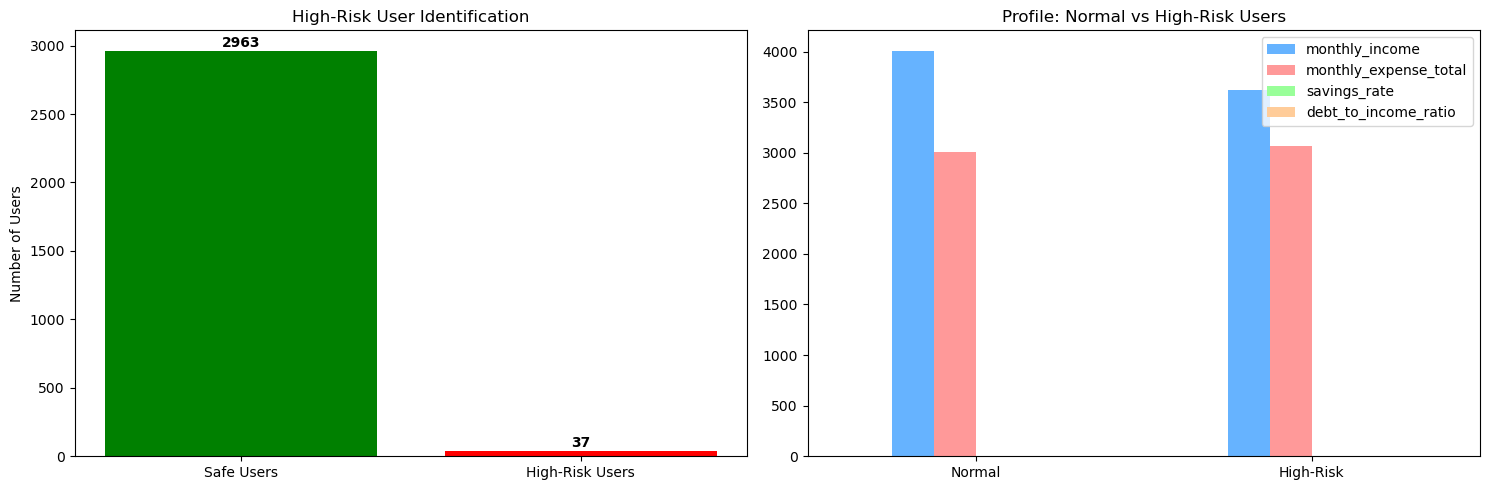

High-risk users: 37 (1.2%)


In [27]:
# Identify high-risk users
high_risk = df[
    (df['savings_rate'] < 0.1) &
    (df['debt_to_income_ratio'] > 0.4) &
    (df['cash_flow_status'] == 'Negative')
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. High-risk user count
categories = ['Safe Users', 'High-Risk Users']
counts = [len(df) - len(high_risk), len(high_risk)]
axes[0].bar(categories, counts, color=['green', 'red'])
axes[0].set_title('High-Risk User Identification')
axes[0].set_ylabel('Number of Users')
for i, v in enumerate(counts):
    axes[0].text(i, v + 30, str(v), ha='center', fontweight='bold')

# 2. Profile comparison
profile = df.groupby(df.index.isin(high_risk.index))[
    ['monthly_income','monthly_expense_total','savings_rate','debt_to_income_ratio']
].mean()
profile.index = ['Normal', 'High-Risk']
profile.plot(kind='bar', ax=axes[1], color=['#66b3ff','#ff9999','#99ff99','#ffcc99'])
axes[1].set_title('Profile: Normal vs High-Risk Users')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

print(f"High-risk users: {len(high_risk)} ({len(high_risk)/len(df)*100:.1f}%)")

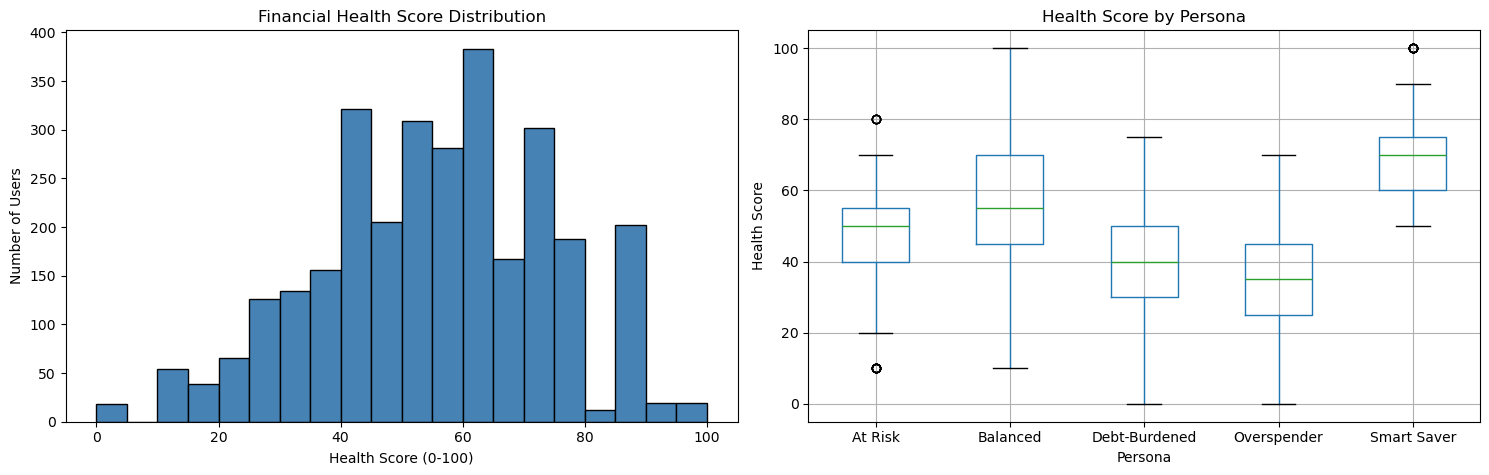

Average health score: 52.9
Users with poor health (<40): 592
Users with good health (>70): 440


In [28]:
def health_score(row):
    score = 0
    score += 30 if row['savings_rate'] > 0.2 else (15 if row['savings_rate'] > 0.1 else 0)
    score += 25 if row['debt_to_income_ratio'] < 0.3 else (10 if row['debt_to_income_ratio'] < 0.5 else 0)
    score += 20 if row['cash_flow_status'] == 'Positive' else 0
    score += 15 if row['savings_goal_met'] else 0
    score += 10 if row['emergency_fund'] > 1000 else 0
    return score

df['health_score'] = df.apply(health_score, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Health score distribution
axes[0].hist(df['health_score'], bins=20, color='steelblue', edgecolor='black')
axes[0].set_title('Financial Health Score Distribution')
axes[0].set_xlabel('Health Score (0-100)')
axes[0].set_ylabel('Number of Users')

# 2. Health score by persona
df.boxplot(column='health_score', by='persona', ax=axes[1])
axes[1].set_title('Health Score by Persona')
axes[1].set_xlabel('Persona')
axes[1].set_ylabel('Health Score')
plt.suptitle('')
plt.tight_layout()
plt.show()

print(f"Average health score: {df['health_score'].mean():.1f}")
print(f"Users with poor health (<40): {(df['health_score'] < 40).sum()}")
print(f"Users with good health (>70): {(df['health_score'] > 70).sum()}")